In [15]:
seeds = [42,21,10]
industry = ['airline','retail','telecom']

In [16]:
import json
from itertools import combinations
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from IPython.display import display

RESULTS_DIR = Path("results_clean_mexlunia")

# dataviz palette: fixed categorical order (one hue per seed) + reserved status colors (pass/fail/mixed)
INK_PRIMARY = "#0b0b0b"
INK_SECONDARY = "#52514e"
INK_MUTED = "#898781"
GRID_HAIRLINE = "#e1e0d9"
SURFACE = "#fcfcfb"

CATEGORICAL = ["#2a78d6", "#eb6834", "#1baf7a"]  # blue, orange, aqua -> one per seed, in seeds[] order
STATUS = {"always_pass": "#0ca30c", "mixed (flips)": "#fab219", "always_fail": "#d03b3b"}

plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "axes.edgecolor": GRID_HAIRLINE,
    "axes.labelcolor": INK_SECONDARY,
    "text.color": INK_PRIMARY,
    "xtick.color": INK_MUTED,
    "ytick.color": INK_MUTED,
    "grid.color": GRID_HAIRLINE,
    "font.size": 11,
})

In [17]:
def find_run_dir(domain, seed):
    matches = sorted(RESULTS_DIR.glob(f"{domain}_*_seed{seed}"))
    return matches[0] if matches else None


def load_simulations(run_dir):
    """All simulations in a run, consolidated from its per-task <domain>_<task_id>_clean.json files (results.json is ignored)."""
    sims = []
    for path in sorted(run_dir.glob("*_clean.json")):
        sims.extend(json.loads(path.read_text())["simulations"])
    return sims


def load_run(domain, seed):
    run_dir = find_run_dir(domain, seed)
    if run_dir is None:
        return None
    rows = []
    for sim in load_simulations(run_dir):
        reward_info = sim.get("reward_info")
        reward = reward_info["reward"] if reward_info is not None else np.nan
        rows.append({
            "domain": domain,
            "seed": seed,
            "task_id": sim["task_id"],
            "reward": reward,
            "passed": reward == 1.0,
            "termination_reason": sim.get("termination_reason"),
        })
    return pd.DataFrame(rows)


runs = []
for domain in industry:
    for seed in seeds:
        df = load_run(domain, seed)
        if df is None:
            print(f"skipping {domain} seed={seed}: no results found in {RESULTS_DIR}/")
            continue
        runs.append(df)

long_df = pd.concat(runs, ignore_index=True)
print(f"loaded {len(long_df)} simulation rows from {len(runs)} runs")
long_df.head()

skipping airline seed=21: no results found in results_clean_mexlunia/
skipping airline seed=10: no results found in results_clean_mexlunia/
skipping retail seed=21: no results found in results_clean_mexlunia/
skipping retail seed=10: no results found in results_clean_mexlunia/
skipping telecom seed=21: no results found in results_clean_mexlunia/
skipping telecom seed=10: no results found in results_clean_mexlunia/
loaded 278 simulation rows from 3 runs


,domain,seed,task_id,reward,passed,termination_reason
0,airline,42,0,1.0,True,user_stop
1,airline,42,10,0.0,False,user_stop
2,airline,42,11,0.0,False,user_stop
3,airline,42,12,1.0,True,user_stop
4,airline,42,13,0.0,False,user_stop


### Data quality check

Some simulations don't end in a clean `user_stop` (infra errors, hitting `max_steps`, or `too_many_errors`). Those have no `reward_info` and are currently counted as **fails** in the pass rate below since the task was never verified complete. Check the breakdown before trusting the numbers.

In [18]:
non_clean = (long_df[long_df["termination_reason"] != "user_stop"]
             .groupby(["domain", "seed", "termination_reason"])
             .size()
             .rename("count"))
display(non_clean.to_frame() if len(non_clean) else "no non-clean terminations")

count
domain  seed termination_reason       
airline 42   max_steps               1
retail  42   max_steps               5
             too_many_errors         2
telecom 42   max_steps               3
             too_many_errors         3

## Overall results

One row per run, with raw counts. `crashed` = tasks that ended in `infrastructure_error` and were never graded: they count as fails in `pass_rate_%` and are left out of `pass_rate_graded_%`. The grid below shows the same numbers as `passed/tasks (pass rate)` by domain and seed.

In [19]:
summary = (long_df
           .assign(crashed=long_df["termination_reason"] == "infrastructure_error")
           .groupby(["domain", "seed"])
           .agg(tasks=("task_id", "size"), passed=("passed", "sum"), crashed=("crashed", "sum")))
summary["failed"] = summary["tasks"] - summary["passed"] - summary["crashed"]
summary["pass_rate_%"] = 100 * summary["passed"] / summary["tasks"]
summary["pass_rate_graded_%"] = 100 * summary["passed"] / (summary["tasks"] - summary["crashed"])
summary = summary[["tasks", "passed", "failed", "crashed", "pass_rate_%", "pass_rate_graded_%"]]
display(summary.round(1))

,,tasks,passed,failed,crashed,pass_rate_%,pass_rate_graded_%
domain,seed,,,,,,
airline,42,50,16,34,0,32.0,32.0
retail,42,114,58,56,0,50.9,50.9
telecom,42,114,33,81,0,28.9,28.9


In [20]:
grid = (summary.apply(lambda r: f"{r['passed']:.0f}/{r['tasks']:.0f} ({r['pass_rate_%']:.1f}%)", axis=1)
        .unstack("seed")
        .reindex(columns=seeds))
display(grid.fillna("—"))

seed,42,21,10
domain,,,
airline,16/50 (32.0%),—,—
retail,58/114 (50.9%),—,—
telecom,33/114 (28.9%),—,—


## Airline: comparison across seeds

Airline is the domain run with all three seeds, each at temperature 0. If reruns are deterministic, the seeds should agree on every task, and the conversations themselves should be identical.

In [21]:
airline = long_df[long_df["domain"] == "airline"]
airline_seeds = [s for s in seeds if s in set(airline["seed"])]

airline_by_seed = summary.xs("airline", level="domain").reindex(airline_seeds)
display(airline_by_seed.round(1))

rates = airline_by_seed["passed"] / airline_by_seed["tasks"]
print(f"pass rate across seeds: mean {rates.mean() * 100:.1f}% | std {rates.std() * 100:.2f} pts | var {rates.var():.5f}")

,tasks,passed,failed,crashed,pass_rate_%,pass_rate_graded_%
seed,,,,,,
42,50,16,34,0,32.0,32.0


pass rate across seeds: mean 32.0% | std nan pts | var nan


### Task by task

Each task is classed by its outcome across the seeds (`always_pass`, `flips`, `always_fail`); any task that flips is listed. The next cell compares the full conversations — every message and tool call, ignoring ids and timestamps.

In [22]:
outcomes = (airline.pivot_table(index="task_id", columns="seed", values="passed", aggfunc="first")
            .reindex(columns=airline_seeds))
n_passed = outcomes.sum(axis=1)
flips = (n_passed > 0) & (n_passed < len(airline_seeds))
consistency = pd.Series({
    "always_pass": int((n_passed == len(airline_seeds)).sum()),
    "flips": int(flips.sum()),
    "always_fail": int((n_passed == 0).sum()),
}, name="tasks")
display(consistency.to_frame())

if flips.any():
    display(outcomes[flips].replace({True: "pass", False: "fail"}))
else:
    print("no task changes outcome between seeds")

,tasks
always_pass,16
flips,0
always_fail,34


no task changes outcome between seeds


In [23]:
def conversation(sim):
    """A run's conversation without ids/timestamps: who said what, and which tools were called with what."""
    return [
        (m.get("role"), (m.get("content") or "").strip(), m.get("error"),
         [(c["name"], json.dumps(c.get("arguments"), sort_keys=True)) for c in m.get("tool_calls") or []])
        for m in sim.get("messages") or []
    ]


conversations = {
    seed: {sim["task_id"]: conversation(sim)
           for sim in load_simulations(find_run_dir("airline", seed))}
    for seed in airline_seeds
}
task_ids = list(conversations[airline_seeds[0]])
first = conversations[airline_seeds[0]]
same_everywhere = sum(all(conversations[s][t] == first[t] for s in airline_seeds) for t in task_ids)
print(f"conversations identical across all {len(airline_seeds)} seeds: {same_everywhere}/{len(task_ids)}")
for a, b in combinations(airline_seeds, 2):
    same = sum(conversations[a][t] == conversations[b][t] for t in task_ids)
    print(f"  seed {a} vs seed {b}: {same}/{len(task_ids)} identical")

conversations identical across all 1 seeds: 50/50


## Domains: comparison for seed 42

Each domain is run once with seed 42. Reruns at temperature 0 are identical, so the remaining uncertainty is which tasks happen to be in each domain: `ci95_low_%`/`ci95_high_%` is a 95% Wilson interval on the pass rate (crashes counted as fails). The last row pools all three domains.

In [24]:
DOMAIN_SEED = 42


def wilson_interval(passed, n, z=1.96):
    p = passed / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centre - half, centre + half


by_domain = summary.xs(DOMAIN_SEED, level="seed")[["tasks", "passed", "failed", "crashed"]].copy()
by_domain.loc["all domains"] = by_domain.sum()
by_domain["pass_rate_%"] = 100 * by_domain["passed"] / by_domain["tasks"]
by_domain["pass_rate_graded_%"] = 100 * by_domain["passed"] / (by_domain["tasks"] - by_domain["crashed"])
low, high = wilson_interval(by_domain["passed"], by_domain["tasks"])
by_domain["ci95_low_%"], by_domain["ci95_high_%"] = 100 * low, 100 * high
display(by_domain.round(1))

,tasks,passed,failed,crashed,pass_rate_%,pass_rate_graded_%,ci95_low_%,ci95_high_%
domain,,,,,,,,
airline,50,16,34,0,32.0,32.0,20.8,45.8
retail,114,58,56,0,50.9,50.9,41.8,59.9
telecom,114,33,81,0,28.9,28.9,21.4,37.9
all domains,278,107,171,0,38.5,38.5,33.0,44.3


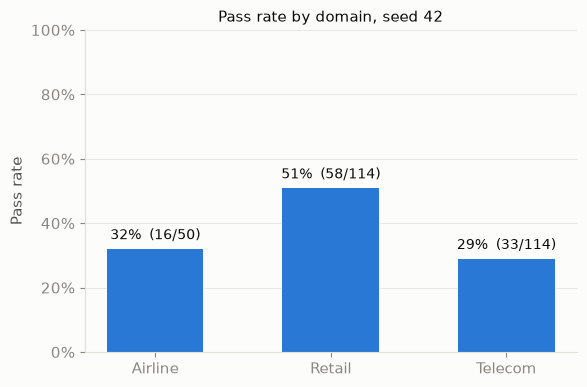

In [25]:
plot = by_domain.drop(index="all domains")
x = np.arange(len(plot))
rate = plot["pass_rate_%"]

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(x, rate, width=0.55, color=CATEGORICAL[0])
for xi, (r, p, n) in enumerate(zip(rate, plot["passed"], plot["tasks"])):
    ax.text(xi, r + 2, f"{r:.0f}%  ({p:.0f}/{n:.0f})", ha="center", va="bottom", color=INK_PRIMARY, fontsize=10)

ax.set_xticks(x)
ax.set_xticklabels([d.capitalize() for d in plot.index])
ax.set_ylabel("Pass rate")
ax.set_ylim(0, 100)
ax.yaxis.set_major_formatter(mticker.PercentFormatter())
ax.grid(axis="y", linewidth=0.5)
ax.set_axisbelow(True)
for spine in ("top", "right"):
    ax.spines[spine].set_visible(False)
ax.set_title(f"Pass rate by domain, seed {DOMAIN_SEED}", fontsize=11)
plt.tight_layout()
plt.show()